# Consolidação dos testes de usabilidade

Consolida as sessões de usabilidade a partir dos dados anonimizados em `docs/usabilidade/dados/`, preenchidos conforme
[`docs/usabilidade/README.md`](../../docs/usabilidade/README.md).

O notebook:

1. valida os valores de cada planilha antes de qualquer cálculo;
2. separa sessões **realizadas**, **bloqueadas** e **não executadas**;
3. apura cada cenário nos estados *concluído*, *concluído com dificuldade*, *falhou* e *não executado*;
4. calcula o SUS de cada participante e o descreve por mediana e amplitude, sem meta de aprovação;
5. lista as ocorrências por severidade e os defeitos críticos sem tratamento ou sem reteste.

Executar a partir de `src/notebooks`. A variável de ambiente `USABILIDADE_DADOS` aponta para outro diretório de dados,
o que permite testar o notebook sem tocar nos arquivos versionados.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

DADOS = Path(os.environ.get('USABILIDADE_DADOS', '../../docs/usabilidade/dados'))
FIGURAS = Path(os.environ.get('USABILIDADE_FIGURAS', '../../docs/img'))

AMOSTRA_MINIMA = 5
RESULTADOS = ['sucesso', 'dificuldade', 'nao_conseguiu', 'nao_testado']
SEVERIDADES = ['alta', 'media', 'baixa', 'cosmetica']
STATUS_SESSAO = ['realizada', 'bloqueada', 'nao_executada']
FAMILIARIDADE = ['baixa', 'media', 'alta']
FAIXAS_ETARIAS = ['18-29', '30-39', '40-49', '50-59', '60+']

participantes = pd.read_csv(DADOS / 'participantes.csv', dtype=str).fillna('')
registro = pd.read_csv(DADOS / 'registro.csv', dtype=str).fillna('')
ocorrencias = pd.read_csv(DADOS / 'ocorrencias.csv', dtype=str).fillna('')
sus = pd.read_csv(DADOS / 'sus.csv', dtype=str).fillna('')
print(f'dados lidos de {DADOS}')

dados lidos de ../../docs/usabilidade/dados


## 1. Validação

Um valor fora do vocabulário do README interrompe a consolidação: um resultado digitado errado não pode virar
estatística silenciosamente. Linhas de participantes cuja sessão não aconteceu podem ficar em branco.

In [2]:
problemas = []

def conferir(tabela, nome, coluna, permitidos, filtro=None):
    linhas = tabela if filtro is None else tabela[filtro]
    for indice, valor in linhas[coluna].items():
        if valor not in permitidos:
            problemas.append(f'{nome}, linha {indice + 2}, {coluna}: {valor!r} fora de {permitidos}')

sessoes_com_status = participantes['status_sessao'] != ''
conferir(participantes, 'participantes.csv', 'status_sessao', STATUS_SESSAO, sessoes_com_status)
realizadas = set(participantes.loc[participantes['status_sessao'] == 'realizada', 'participante'])
p_realizadas = participantes['participante'].isin(realizadas)
conferir(participantes, 'participantes.csv', 'externo_a_turma', ['sim'], p_realizadas)
conferir(participantes, 'participantes.csv', 'familiaridade_tecnologica', FAMILIARIDADE, p_realizadas)
conferir(participantes, 'participantes.csv', 'familiaridade_agentes', FAMILIARIDADE + ['nao_informada'], p_realizadas)
conferir(participantes, 'participantes.csv', 'faixa_etaria', FAIXAS_ETARIAS, p_realizadas)
for indice, linha in participantes[p_realizadas].iterrows():
    if not linha['sessao']:
        problemas.append(f"participantes.csv, linha {indice + 2}: sessão realizada sem identificador de sessão")
for indice, linha in participantes[p_realizadas].iterrows():
    if not linha['commit_testado']:
        problemas.append(f"participantes.csv, linha {indice + 2}: sessão realizada sem commit_testado")
    if not linha['moderador']:
        problemas.append(f"participantes.csv, linha {indice + 2}: sessão realizada sem moderador")
for indice, linha in participantes[participantes['status_sessao'] == 'bloqueada'].iterrows():
    if not linha['motivo_status']:
        problemas.append(f"participantes.csv, linha {indice + 2}: sessão bloqueada sem motivo")

r_realizadas = registro['participante'].isin(realizadas)
for coluna in ['resultado_geral', 'etapa_1', 'etapa_2', 'etapa_3', 'etapa_4', 'etapa_5']:
    conferir(registro, 'registro.csv', coluna, RESULTADOS, r_realizadas)
conferir(registro, 'registro.csv', 'dica_dada', ['sim', 'nao'], r_realizadas)
for indice, linha in registro[r_realizadas].iterrows():
    etapas = [linha[f'etapa_{n}'] for n in range(1, 6)]
    if linha['resultado_geral'] == 'nao_testado' and not linha['observacoes']:
        problemas.append(f'registro.csv, linha {indice + 2}: nao_testado sem a dependência nomeada nas observações')
    if linha['dica_dada'] == 'sim' and 'nao_conseguiu' not in etapas:
        problemas.append(f'registro.csv, linha {indice + 2}: dica dada sem etapa registrada como nao_conseguiu')

conferir(ocorrencias, 'ocorrencias.csv', 'severidade', SEVERIDADES)
conferir(ocorrencias, 'ocorrencias.csv', 'defeito_critico', ['sim', 'nao'])
sessoes = set(participantes.loc[p_realizadas, 'sessao'])
origens = realizadas | sessoes | {'verificacao_posterior'}
fora = sorted(set(ocorrencias['participante']) - origens)
if fora:
    problemas.append(f'ocorrencias.csv: origem que não é participante, sessão realizada nem verificacao_posterior: {fora}')

itens = [f'q{n}' for n in range(1, 11)]
for indice, linha in sus.iterrows():
    for item in itens:
        if linha[item] not in {'', '1', '2', '3', '4', '5'}:
            problemas.append(f'sus.csv, linha {indice + 2}, {item}: {linha[item]!r} fora de 1 a 5')

if problemas:
    print('\n'.join(problemas))
    raise ValueError(f'{len(problemas)} problema(s) nos dados; corrigir antes de consolidar')
print('dados válidos')

dados válidos


## 2. Sessões

O planejamento exige ao menos cinco participantes externos à turma. Cada participante pertence a uma sessão; em sessões
individuais cada cenário tem uma observação por participante, e quando vários participantes fazem as tarefas na
mesma sessão a observação do cenário vale para todos.

In [3]:
contagem = participantes['status_sessao'].replace('', 'sem registro').value_counts()
print(contagem.to_string())
amostra_suficiente = len(realizadas) >= AMOSTRA_MINIMA
print()
print(f'participantes com sessão realizada: {len(realizadas)} de {AMOSTRA_MINIMA} exigidos '
      f'— amostra {"suficiente" if amostra_suficiente else "INSUFICIENTE"}')

perfis = participantes[p_realizadas][['participante', 'sessao', 'vaga_perfil',
                                     'familiaridade_tecnologica', 'familiaridade_agentes', 'faixa_etaria',
                                     'commit_testado']]
por_sessao = perfis.groupby('sessao')['participante'].count()
print()
print('participantes por sessão:')
print(por_sessao.to_string())
print(f'observações das tarefas: {len(por_sessao)}')
commits = set(perfis['commit_testado'])
if len(commits) > 1:
    print(f'ATENÇÃO: sessões em versões diferentes: {sorted(commits)}')
vagas_vazias = participantes.loc[~p_realizadas & (participantes['vaga_perfil'] != 'reserva'), 'vaga_perfil'].tolist()
if vagas_vazias:
    print(f'vagas de perfil sem sessão realizada: {vagas_vazias}')
familiaridades = set(perfis['familiaridade_agentes'])
if realizadas and not {'baixa', 'alta'} <= familiaridades:
    print(f'ATENÇÃO: a amostra não reúne familiaridade baixa e alta com agentes: {sorted(familiaridades)}')
perfis

status_sessao
realizada    6

participantes com sessão realizada: 6 de 5 exigidos — amostra suficiente

participantes por sessão:
sessao
S1    1
S2    1
S3    1
S4    1
S5    1
S6    1
observações das tarefas: 6


,participante,sessao,vaga_perfil,familiaridade_tecnologica,familiaridade_agentes,faixa_etaria,commit_testado
0,P1,S1,estudante_de_tecnologia,alta,alta,18-29,c9ad16a
1,P2,S2,estudante_de_tecnologia,alta,media,18-29,c9ad16a
2,P3,S3,estudante_de_tecnologia,media,baixa,18-29,c9ad16a
3,P4,S4,estudante_de_tecnologia,alta,media,18-29,c9ad16a
4,P5,S5,estudante_de_tecnologia,alta,alta,18-29,c9ad16a
5,P6,S6,estudante_de_tecnologia,media,baixa,18-29,c9ad16a


## 3. Resultado por cenário

Estados apurados: *concluído* (`sucesso`), *concluído com dificuldade* (`dificuldade`), *falhou*
(`nao_conseguiu`) e *não executado* (`nao_testado`). Sessões bloqueadas não entram aqui; aparecem na seção 2.

In [4]:
ESTADOS = {'sucesso': 'concluído', 'dificuldade': 'concluído com dificuldade',
           'nao_conseguiu': 'falhou', 'nao_testado': 'não executado'}
executado = registro[r_realizadas].copy()
executado['estado'] = executado['resultado_geral'].map(ESTADOS)
por_cenario = (executado.pivot_table(index=['cenario', 'tarefa'], columns='estado', values='participante',
                                     aggfunc='count', fill_value=0)
               .reindex(columns=list(ESTADOS.values()), fill_value=0))
por_cenario

,estado,concluído,concluído com dificuldade,falhou,não executado
cenario,tarefa,,,,
1,Entrada em linguagem natural,4,2,0,0
2,Consulta de status e prazo,5,1,0,0
3,Consulta de riscos e informações do projeto,2,2,2,0
4,Análise e comparação entre projetos,4,2,0,0
5,Informação ausente ou fora de escopo,0,4,2,0
6,Sugestão proativa e controle do usuário,0,4,2,0
7,Entrada por voz,4,2,0,0


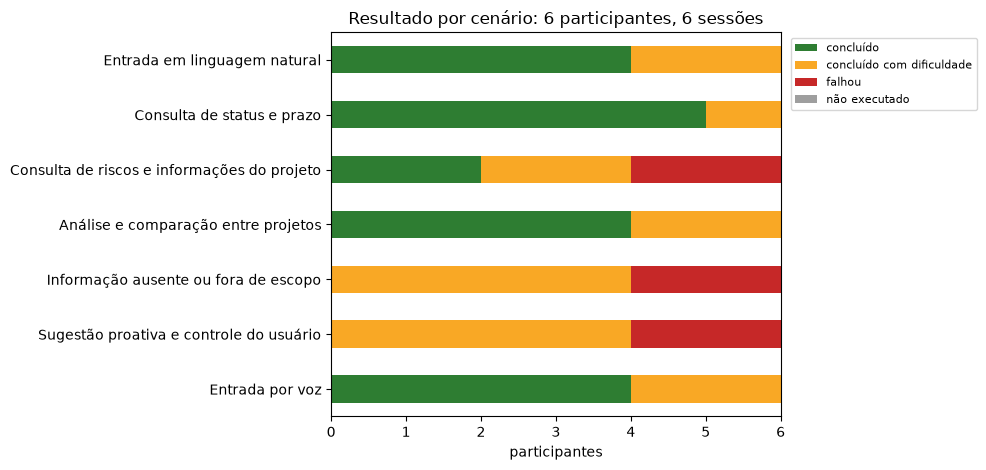

In [5]:
if len(executado):
    FIGURAS.mkdir(parents=True, exist_ok=True)
    cores = ['#2e7d32', '#f9a825', '#c62828', '#9e9e9e']
    tabela = por_cenario.droplevel(0)
    eixo = tabela.plot(kind='barh', stacked=True, color=cores, figsize=(10, 4.8))
    eixo.invert_yaxis()
    eixo.set_xlabel('participantes')
    eixo.set_ylabel('')
    n_sessoes = perfis['sessao'].nunique()
    eixo.set_title(f'Resultado por cenário: {len(realizadas)} participantes, '
                   f'{n_sessoes} {"sessões" if n_sessoes > 1 else "sessão"}')
    eixo.legend(fontsize=8, loc='upper left', bbox_to_anchor=(1.01, 1))
    plt.tight_layout()
    plt.savefig(FIGURAS / 'usabilidade-resultado-por-cenario.png', dpi=150, bbox_inches='tight')
    plt.show()

## 4. Etapas com mais dificuldade

As etapas em que mais participantes hesitaram, falharam ou precisaram de dica. É a leitura que aponta o que
corrigir; o SUS, sozinho, não aponta.

In [6]:
linhas = []
for _, linha in executado.iterrows():
    for n in range(1, 6):
        linhas.append({'cenario': linha['cenario'], 'tarefa': linha['tarefa'], 'etapa': n,
                       'resultado': linha[f'etapa_{n}']})
etapas = pd.DataFrame(linhas, columns=['cenario', 'tarefa', 'etapa', 'resultado'])
testadas = etapas[etapas['resultado'] != 'nao_testado']
if len(testadas):
    resumo = (testadas.assign(problema=testadas['resultado'].isin(['dificuldade', 'nao_conseguiu']))
              .groupby(['cenario', 'tarefa', 'etapa'])['problema'].agg(['sum', 'count'])
              .rename(columns={'sum': 'com_problema', 'count': 'participantes'}))
    resumo = resumo[resumo['com_problema'] > 0].sort_values('com_problema', ascending=False)
    display(resumo.head(10))
dicas = executado[executado['dica_dada'] == 'sim'][['participante', 'cenario', 'tarefa']]
print(f'dicas dadas: {len(dicas)}')
dicas

com_problema  \
cenario tarefa                                      etapa                 
5       Informação ausente ou fora de escopo        4                 6   
6       Sugestão proativa e controle do usuário     5                 6   
3       Consulta de riscos e informações do projeto 3                 4   
                                                    5                 4   
6       Sugestão proativa e controle do usuário     4                 3   
                                                    2                 3   
5       Informação ausente ou fora de escopo        5                 3   
1       Entrada em linguagem natural                1                 2   
2       Consulta de status e prazo                  4                 2   
7       Entrada por voz                             1                 2   

                                                           participantes  
cenario tarefa                                      etapa                 
5       Informação ausente ou fora de escopo        4                  6  
6       Sugestão proativa e controle do usuário     5                  6  
3       Consulta de riscos e informações do projeto 3                  6  
                                                    5                  6  
6       Sugestão proativa e controle do usuário     4                  6  
                                                    2                  6  
5       Informação ausente ou fora de escopo        5                  6  
1       Entrada em linguagem natural                1                  6  
2       Consulta de status e prazo                  4                  6  
7       Entrada por voz                             1                  6

dicas dadas: 4


,participante,cenario,tarefa
18,P3,5,Informação ausente ou fora de escopo
19,P3,6,Sugestão proativa e controle do usuário
25,P4,5,Informação ausente ou fora de escopo
40,P6,6,Sugestão proativa e controle do usuário


## 5. SUS

Dado descritivo, sem meta de aprovação (ver [`questionario-sus.md`](../../docs/usabilidade/questionario-sus.md)).
Itens ímpares contribuem com resposta − 1; pares, com 5 − resposta; a soma multiplicada por 2,5 dá o SUS de 0 a 100.
Resposta em branco invalida o SUS daquela resposta.

O formulário não identifica quem respondeu: as respostas entram como `R1`, `R2`… na ordem de envio, sem vínculo
com os códigos `P1`–`P6`, e são comparadas só em número com os participantes.

In [7]:
def pontuar(linha):
    if any(linha[item] == '' for item in itens):
        return None
    valores = [int(linha[item]) for item in itens]
    soma = sum(v - 1 if n % 2 == 1 else 5 - v for n, v in enumerate(valores, start=1))
    return soma * 2.5

respostas = sus[sus[itens].ne('').any(axis=1)].copy()
respostas['sus'] = respostas.apply(pontuar, axis=1)
invalidos = respostas.loc[respostas['sus'].isna(), 'resposta'].tolist()
validos = respostas.dropna(subset=['sus'])
print(f'respostas ao formulário: {len(respostas)} | participantes com sessão realizada: {len(realizadas)}')
print(f'SUS válidos: {len(validos)}; inválidos (resposta em branco): {invalidos or "nenhum"}')
if len(validos):
    print(f"mediana {validos['sus'].median():.2f} | amplitude {validos['sus'].min():.1f} a {validos['sus'].max():.1f} "
          f"| média {validos['sus'].mean():.1f} com n = {len(validos)}")
validos[['resposta', 'enviada_em', 'sus']]

respostas ao formulário: 6 | participantes com sessão realizada: 6
SUS válidos: 6; inválidos (resposta em branco): nenhum
mediana 83.75 | amplitude 75.0 a 100.0 | média 86.2 com n = 6


,resposta,enviada_em,sus
0,R1,2026-09-23 16:56:35,97.5
1,R2,2026-09-23 16:58:54,100.0
2,R3,2026-09-23 16:59:47,87.5
3,R4,2026-09-23 17:00:08,80.0
4,R5,2026-09-23 17:01:11,77.5
5,R6,2026-09-23 17:05:45,75.0


## 6. Ocorrências e defeitos críticos

Todo defeito crítico precisa estar corrigido ou ter impedimento declarado, e precisa de reteste.

In [8]:
if len(ocorrencias):
    por_severidade = (ocorrencias.pivot_table(index='cenario', columns='severidade', values='id',
                                              aggfunc='count', fill_value=0)
                      .reindex(columns=SEVERIDADES, fill_value=0))
    display(por_severidade)
criticos = ocorrencias[ocorrencias['defeito_critico'] == 'sim']
pendentes = criticos[(criticos['tratamento'] == '') | (~criticos['reteste'].isin(['aprovado', 'reprovado']))]
altas_sem_avaliacao = ocorrencias[(ocorrencias['severidade'] == 'alta') & (ocorrencias['defeito_critico'] == '')]
print(f'ocorrências: {len(ocorrencias)} | defeitos críticos: {len(criticos)} | '
      f'críticos sem tratamento ou reteste concluído: {len(pendentes)}')
if len(altas_sem_avaliacao):
    print(f'ATENÇÃO: {len(altas_sem_avaliacao)} ocorrência(s) alta(s) sem avaliação de defeito crítico')
criticos[['id', 'cenario', 'participante', 'resumo', 'tratamento', 'reteste']]

severidade,alta,media,baixa,cosmetica
cenario,,,,
3,1,0,0,0
4,0,0,2,0
5,0,1,0,0
6,0,2,0,0
7,0,1,0,1


ocorrências: 8 | defeitos críticos: 1 | críticos sem tratamento ou reteste concluído: 0


,id,cenario,participante,resumo,tratamento,reteste
6,O7,3,P1,A pergunta sobre riscos e avanços recebeu como...,Corrigido em app/gemini/client.py: limite de 1...,aprovado


## 7. Comentários abertos

Respostas às três perguntas do encerramento, já anonimizadas, para a síntese qualitativa da Seção 9.3.2.

In [9]:
for _, linha in respostas[respostas['comentario_aberto'] != ''].iterrows():
    print(f"{linha['resposta']}: {linha['comentario_aberto']}\n")